# **Setup**

In [1]:
import torch, math
from torch import nn
import numpy as np
import torch.nn.functional as F
from dataclasses import dataclass
from datasets import load_dataset
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained('gpt2')

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [2]:
torch.__version__

'2.14.1+cu130'

In [3]:
!pip install -q datasets transformers
from google.colab import drive
drive.mount('/content/drive')

import os
DATA_DIR = '/content/drive/MyDrive/looped/data'
os.makedirs(DATA_DIR, exist_ok=True)

Mounted at /content/drive


# **Tokenized 10% of the TinyStories dataset using GPT2**
**This is a small scale implementation of looped tranformers**

In [4]:
EOS = tok.eos_token_id

# TinyStories
ds = load_dataset('roneneldan/TinyStories', split='train[:10%]')
text_key = 'text'

def tokenize(batch):
    ids = tok(batch[text_key])['input_ids']
    return {'ids': [x + [EOS] for x in ids]}

tokenized = ds.map(tokenize, batched=True, remove_columns=ds.column_names,
                   num_proc=2)

arr = np.concatenate([np.array(x, dtype=np.uint16) for x in tokenized['ids']])
print(f'{len(arr)/1e6:.1f}M tokens')

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-5852b56a2bd28f(…): reconstructing file:   0%|          |  0.00B /  248MB            

data/train-00001-of-00004-5852b56a2bd28f(…): downloading bytes:           |  0.00B            

data/train-00002-of-00004-a26307300439e9(…): reconstructing file:   0%|          |  0.00B /  246MB            

... (6 outputs left out)

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

Map (num_proc=2):   0%|          | 0/211972 [00:00<?, ? examples/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1057 > 1024). Running this sequence through the model will result in indexing errors
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1106 > 1024). Running this sequence through the model will result in indexing errors


47.7M tokens


In [5]:
print(tokenized[0]['ids'][:20])
print(tok.decode(tokenized[0]['ids'][:20]))

[3198, 1110, 11, 257, 1310, 2576, 3706, 20037, 1043, 257, 17598, 287, 607, 2119, 13, 1375, 2993, 340, 373, 2408]
One day, a little girl named Lily found a needle in her room. She knew it was difficult


# **Saved the tokenized dataset to Drive**

In [6]:
n_val = int(0.01 * len(arr))
arr[:-n_val].tofile(f'{DATA_DIR}/train.bin')
arr[-n_val:].tofile(f'{DATA_DIR}/val.bin')

In [7]:
!ls -lh {DATA_DIR}

total 91M
-rw------- 1 root root  91M Nov 14 23:13 train.bin
-rw------- 1 root root 932K Nov 14 23:13 val.bin


In [8]:
train = np.memmap(f'{DATA_DIR}/train.bin', dtype=np.uint16, mode='r')
val   = np.memmap(f'{DATA_DIR}/val.bin',   dtype=np.uint16, mode='r')

def get_batch(data, batch_size, ctx):
    ix = np.random.randint(0, len(data) - ctx - 1, batch_size)
    x = np.stack([data[i:i+ctx] for i in ix]).astype(np.int64)
    y = np.stack([data[i+1:i+1+ctx] for i in ix]).astype(np.int64)
    return torch.from_numpy(x).cuda(), torch.from_numpy(y).cuda()

In [9]:
x, y = get_batch(train, 4, 8)
print(x.shape, y.shape)          # torch.Size([4, 8]) torch.Size([4, 8])
print(tok.decode(x[0]), '|', tok.decode(y[0]))

torch.Size([4, 8]) torch.Size([4, 8])
 saw something behind them.

" |  something behind them.

"Oh


In [10]:
@dataclass
class Config:
    vocab: int = 50257
    ctx: int = 256
    d: int = 384
    n_heads: int = 6
    n_prelude: int = 1
    n_core: int = 3
    n_coda: int = 1
    inject: str = "constrained"   # "free" or "constrained"

class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__()
        self.w = nn.Parameter(torch.ones(d)); self.eps = eps
    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.w

In [11]:
class Attn(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.h = c.n_heads
        self.qkv = nn.Linear(c.d, 3 * c.d, bias=False)
        self.o = nn.Linear(c.d, c.d, bias=False)
    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(x).view(B, T, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        return self.o(y.transpose(1, 2).reshape(B, T, D))

class MLP(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.up = nn.Linear(c.d, 4 * c.d, bias=False)
        self.down = nn.Linear(4 * c.d, c.d, bias=False)
    def forward(self, x):
        return self.down(F.gelu(self.up(x)))

class Block(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.n1, self.n2 = RMSNorm(c.d), RMSNorm(c.d)
        self.attn, self.mlp = Attn(c), MLP(c)
    def forward(self, x):
        x = x + self.attn(self.n1(x))
        return x + self.mlp(self.n2(x))

In [12]:
class Injection(nn.Module):
    """Diagonal SSM-style discretization: A_bar = exp(-dt * exp(log_a)), B_bar = dt * B."""
    def __init__(self, c):
        super().__init__()
        self.mode = c.inject
        if self.mode == "free":
            self.a = nn.Parameter(torch.ones(c.d))        # unconstrained ablation
        else:
            self.log_a = nn.Parameter(torch.zeros(c.d))   # A_cont = -exp(log_a) < 0
            self.log_dt = nn.Parameter(torch.zeros(c.d))  # dt = softplus(log_dt) > 0

    def forward(self):
        if self.mode == "free":
            return self.a, None                           # no discretization, B_bar = B
        dt = F.softplus(self.log_dt)
        return torch.exp(-dt * torch.exp(self.log_a)), dt

In [13]:
def sample_loops(B, mean=6, lo=1, hi=12, device="cuda"):
    """One recurrence count PER SEQUENCE (Poisson, clamped)."""
    n = torch.poisson(torch.full((B,), float(mean), device=device))
    return n.clamp(lo, hi).long()

class LoopedLM(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.c = c
        self.tok = nn.Embedding(c.vocab, c.d)
        self.pos = nn.Embedding(c.ctx, c.d)
        self.prelude = nn.ModuleList([Block(c) for _ in range(c.n_prelude)])
        self.core = nn.ModuleList([Block(c) for _ in range(c.n_core)])
        self.coda = nn.ModuleList([Block(c) for _ in range(c.n_coda)])
        self.inj = Injection(c)
        self.norm_e = RMSNorm(c.d)
        self.B = nn.Linear(c.d, c.d, bias=False)   # input projection
        self.C = nn.Linear(c.d, c.d, bias=False)   # NEW: readout projection
        self.norm_f = RMSNorm(c.d)
        self.head = nn.Linear(c.d, c.vocab, bias=False)
        self.head.weight = self.tok.weight
        self.apply(self._init)
        nn.init.eye_(self.C.weight)                # start C as identity (my choice)

    def _init(self, m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, std=0.02)

    def forward(self, idx, n_loops=4, k_grad=2, targets=None, return_norms=False):
        B, T = idx.shape
        dev = idx.device
        x = self.tok(idx) + self.pos(torch.arange(T, device=dev))
        for blk in self.prelude:
            x = blk(x)

        A, dt = self.inj()
        Bbar = self.B(self.norm_e(x))
        if dt is not None:
            Bbar = Bbar * dt                       # NEW: Delta factor on the input injection

        # NEW: per-sequence loop counts (int -> same for all, tensor (B,) -> one per sequence)
        if isinstance(n_loops, int):
            n_vec = torch.full((B,), n_loops, device=dev, dtype=torch.long)
        else:
            n_vec = n_loops.to(dev)
        n_list = n_vec.tolist()
        grad_on = torch.is_grad_enabled()

        h = torch.zeros_like(x)
        norms = []
        for t in range(int(max(n_list))):
            active = (t < n_vec).view(B, 1, 1)                 # sequence still looping
            keep_grad = (t > n_vec - k_grad).view(B, 1, 1)     # h carries gradient from earlier loop
            need_grad = grad_on and any(n - k_grad <= t < n for n in n_list)
            with torch.set_grad_enabled(need_grad):
                h_in = torch.where(keep_grad, h, h.detach())   # cut gradient before each seq's window
                h_new = A * h_in + Bbar
                for blk in self.core:
                    h_new = blk(h_new)
                h = torch.where(active, h_new, h)              # finished sequences stay frozen
            if return_norms:
                norms.append(h.detach().float().pow(2).mean().sqrt().item())

        h = self.C(h)                                          # NEW: readout before the coda
        for blk in self.coda:
            h = blk(h)
        logits = self.head(self.norm_f(h))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss, norms

In [14]:
dev = "cuda"
for mode in ["free", "constrained"]:
    m = LoopedLM(Config(inject=mode)).to(dev)
    x, y = get_batch(train, 8, 256)
    n = sample_loops(8, mean=6, hi=12)
    print(mode, "loops per sequence:", n.tolist())
    _, loss, norms = m(x, n_loops=n, k_grad=2, targets=y, return_norms=True)
    loss.backward()
    print(f"  {sum(p.numel() for p in m.parameters())/1e6:.1f}M params | loss {loss.item():.2f}")
    print("  h RMS per step:", [round(v, 2) for v in norms])
    print("  core grad ok:", m.core[0].attn.qkv.weight.grad is not None,
          "| C grad ok:", m.C.weight.grad is not None,
          "| max A:", m.inj()[0].max().item())

free loops per sequence: [4, 6, 2, 7, 8, 3, 10, 8]
  28.5M params | loss 10.91
  h RMS per step: [0.53, 1.05, 1.51, 1.93, 2.29, 2.67, 2.99, 3.24, 3.33, 3.42]
  core grad ok: True | C grad ok: True | max A: 1.0
constrained loops per sequence: [5, 9, 6, 8, 4, 3, 7, 2]
  28.5M params | loss 10.88
  h RMS per step: [0.44, 0.66, 0.76, 0.8, 0.82, 0.83, 0.83, 0.83, 0.83]
  core grad ok: True | C grad ok: True | max A: 0.5


In [15]:
import time, json

In [16]:
DATA_DIR = '/content/drive/MyDrive/looped/data'
!cp {DATA_DIR}/*.bin /content/
!ls -lh /content/*.bin

-rw------- 1 root root  91M Nov 14 23:13 /content/train.bin
-rw------- 1 root root 932K Nov 14 23:13 /content/val.bin


In [17]:
import numpy as np

In [18]:
train = np.memmap('/content/train.bin', dtype=np.uint16, mode='r')
val   = np.memmap('/content/val.bin',   dtype=np.uint16, mode='r')

def get_batch(data, batch_size, ctx, rng):
    ix = rng.integers(0, len(data) - ctx - 1, batch_size)
    x = np.stack([data[i:i+ctx] for i in ix]).astype(np.int64)
    y = np.stack([data[i+1:i+1+ctx] for i in ix]).astype(np.int64)
    return torch.from_numpy(x).cuda(), torch.from_numpy(y).cuda()

# Fixed validation set: identical windows for every run
_vrng = np.random.default_rng(1234)
VAL = [get_batch(val, 16, 256, _vrng) for _ in range(16)]

RUN_DIR = '/content/drive/MyDrive/looped/runs'
os.makedirs(RUN_DIR, exist_ok=True)

# Checks
print(len(train), len(val), len(VAL), VAL[0][0].shape)
print(bool((VAL[0][0][:, 1:] == VAL[0][1][:, :-1]).all()))   # y is x shifted by one: expect True

47201382 476781 16 torch.Size([16, 256])
True


In [19]:
@torch.no_grad()
def evaluate(model, Ts):
    model.eval()
    out = {}
    for T in Ts:
        tl = ta = 0.0
        for x, y in VAL:
            with torch.autocast('cuda', dtype=torch.float16):
                logits, loss, _ = model(x, n_loops=T, targets=y)
            tl += loss.item()
            ta += (logits.argmax(-1) == y).float().mean().item()
        n = len(VAL)
        out[T] = dict(val_loss=tl / n,
                      val_ppl=math.exp(min(tl / n, 20)),
                      val_acc=ta / n)
    model.train()
    return out

@torch.no_grad()
def state_norms(model, T=16):
    model.eval()
    x, _ = VAL[0]
    with torch.autocast('cuda', dtype=torch.float16):
        _, _, norms = model(x, n_loops=T, return_norms=True)
    model.train()
    return norms

In [20]:
m = LoopedLM(Config(inject="constrained")).cuda()
print(evaluate(m, [1, 4]))
print([round(v, 2) for v in state_norms(m, 8)])
del m

{1: {'val_loss': 10.889276027679443, 'val_ppl': 53598.48210275453, 'val_acc': 0.0}, 4: {'val_loss': 10.896824479103088, 'val_ppl': 54004.598487846575, 'val_acc': 0.0}}
[0.44, 0.66, 0.77, 0.83, 0.86, 0.87, 0.88, 0.89]


In [21]:
def make_optimizer(model, lr, wd=0.1):
    decay    = [p for p in model.parameters() if p.dim() >= 2]   # weight matrices, embeddings
    no_decay = [p for p in model.parameters() if p.dim() < 2]    # norm scales, A / dt parameters
    return torch.optim.AdamW(
        [{'params': decay,    'weight_decay': wd},
         {'params': no_decay, 'weight_decay': 0.0}],
        lr=lr, betas=(0.9, 0.95))

def lr_at(step, steps, lr, warm=100, min_frac=0.1):
    if step < warm:                                   # linear warmup
        return lr * (step + 1) / warm
    p = (step - warm) / max(1, steps - warm)          # progress through the rest of training
    return lr * (min_frac + (1 - min_frac) * 0.5 * (1 + math.cos(math.pi * p)))   # cosine decay

In [22]:
m = LoopedLM(Config(inject="constrained")).cuda()
opt = make_optimizer(m, 6e-4)
print([(len(g['params']), sum(p.numel() for p in g['params'])) for g in opt.param_groups])
print([round(lr_at(s, 4000, 6e-4), 6) for s in [0, 50, 99, 100, 2000, 3999]])
del m, opt

[(24, 28539264), (14, 5376)]
[6e-06, 0.000306, 0.0006, 0.0006, 0.000341, 6e-05]


In [23]:
def run(name, inject="constrained", k_grad=2, mean_loops=6, steps=4000, lr=6e-4,
        batch=16, seed=0, eval_every=500, log_every=20,
        final_Ts=(1, 2, 4, 6, 8, 12, 16, 24)):

    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    cfg = Config(inject=inject)
    model = LoopedLM(cfg).cuda()
    opt = make_optimizer(model, lr)
    scaler = torch.amp.GradScaler('cuda')

    log, evals = [], []
    ema, spikes, nonfinite, start = None, 0, 0, 0

    ckpt = f'{RUN_DIR}/{name}.pt'
    if os.path.exists(ckpt):                       # resume after a disconnect
        s = torch.load(ckpt, map_location='cuda')
        model.load_state_dict(s['model']); opt.load_state_dict(s['opt'])
        scaler.load_state_dict(s['scaler'])
        start, log, evals = s['step'], s['log'], s['evals']
        ema, spikes, nonfinite = s['ema'], s['spikes'], s['nonfinite']
        rng = np.random.default_rng(seed + start)
        print(f'resumed {name} at step {start}')

    torch.cuda.reset_peak_memory_stats()
    t0 = time.time()

    for step in range(start, steps):
        for g in opt.param_groups:
            g['lr'] = lr_at(step, steps, lr)

        x, y = get_batch(train, batch, cfg.ctx, rng)
        n = sample_loops(batch, mean=mean_loops, lo=1, hi=2 * mean_loops)

        with torch.autocast('cuda', dtype=torch.float16):
            _, loss, _ = model(x, n_loops=n, k_grad=k_grad, targets=y)

        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        gn = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0).item()
        scaler.step(opt)
        scaler.update()

        l = loss.item()
        if not math.isfinite(l):
            nonfinite += 1
        else:
            if ema is not None and step > 200 and l > 1.5 * ema:
                spikes += 1
            ema = l if ema is None else 0.98 * ema + 0.02 * l

        if step % log_every == 0:
            log.append(dict(step=step, loss=l, grad_norm=gn, clipped=int(gn > 1.0),
                            spikes=spikes, nonfinite=nonfinite,
                            max_A=model.inj()[0].max().item(),
                            lr=lr_at(step, steps, lr), time=time.time() - t0,
                            mem_gb=torch.cuda.max_memory_allocated() / 1e9))

        if (step + 1) % eval_every == 0:
            ev = evaluate(model, [4, 8])
            evals.append(dict(step=step + 1, evals=ev, state_norms=state_norms(model, 16)))
            print(f'{name} step {step+1} | train {l:.3f} | val@8 {ev[8]["val_loss"]:.3f} '
                  f'| gn {gn:.2f} | spikes {spikes} | nonfinite {nonfinite} | {time.time()-t0:.0f}s')
            torch.save(dict(model=model.state_dict(), opt=opt.state_dict(),
                            scaler=scaler.state_dict(), step=step + 1, log=log,
                            evals=evals, ema=ema, spikes=spikes, nonfinite=nonfinite), ckpt)

    final = evaluate(model, list(final_Ts))
    result = dict(name=name, inject=inject, k_grad=k_grad, mean_loops=mean_loops,
                  seed=seed, steps=steps, lr=lr, spikes=spikes, nonfinite=nonfinite,
                  train_time_s=time.time() - t0,
                  peak_mem_gb=torch.cuda.max_memory_allocated() / 1e9,
                  final=final, final_state_norms=state_norms(model, 16),
                  evals=evals, log=log)
    with open(f'{RUN_DIR}/{name}.json', 'w') as f:
        json.dump(result, f)
    print(name, 'done |', {T: round(v['val_loss'], 3) for T, v in final.items()})
    return result

In [24]:
r = run("timing", steps=50, eval_every=10**9, final_Ts=(4,))
print(f"{r['train_time_s'] / 50:.2f} s/step | peak mem {r['peak_mem_gb']:.1f} GB")
print("first / last logged loss:", r['log'][0]['loss'], r['log'][-1]['loss'])
os.remove(f'{RUN_DIR}/timing.json')

timing done | {4: 6.506}
0.29 s/step | peak mem 5.9 GB
first / last logged loss: 10.85184097290039 7.5584893226623535


In [25]:
STEPS = 6000
r_free = run("s1_free_seed0", inject="free", k_grad=2, steps=STEPS, seed=0)

KeyboardInterrupt: 

In [27]:
r = json.load(open(f'{RUN_DIR}/s1_free_seed0.json'))
log = r['log']
gn = [d['grad_norm'] for d in log]

print('grad norm | max:', round(max(gn), 2), '| mean:', round(sum(gn) / len(gn), 2))
print('clipped fraction:', round(sum(d['clipped'] for d in log) / len(log), 3))
print('max_A | first:', round(log[0]['max_A'], 3), '| last:', round(log[-1]['max_A'], 3),
      '| peak:', round(max(d['max_A'] for d in log), 3))
print('final state norms:', [round(v, 2) for v in r['final_state_norms']])
print('loss spikes / nonfinite:', r['spikes'], r['nonfinite'])

grad norm | max: 2.27 | mean: 0.66
clipped fraction: 0.017
max_A | first: 1.0 | last: 1.014 | peak: 1.038
final state norms: [1.79, 3.31, 4.78, 6.22, 7.62, 8.99, 10.32, 11.61, 12.88, 14.1, 15.3, 16.47, 17.61, 18.72, 19.81, 20.87]
loss spikes / nonfinite: 0 0


In [ ]:
r_con = run("s1_constrained_seed0", inject="constrained", k_grad=2, steps=STEPS, seed=0)

In [28]:
def summarize(name):
    r = json.load(open(f'{RUN_DIR}/{name}.json'))
    log = r['log']
    gn = [d['grad_norm'] for d in log]
    print(f"== {name}")
    print('  grad norm max/mean:', round(max(gn), 2), '/', round(sum(gn) / len(gn), 2),
          '| clipped frac:', round(sum(d['clipped'] for d in log) / len(log), 3))
    print('  max_A first/last/peak:', round(log[0]['max_A'], 3), round(log[-1]['max_A'], 3),
          round(max(d['max_A'] for d in log), 3))
    print('  state norms:', [round(v, 2) for v in r['final_state_norms']])
    print('  spikes/nonfinite:', r['spikes'], r['nonfinite'],
          '| peak mem GB:', round(r['peak_mem_gb'], 1))

summarize('s1_free_seed0')
summarize('s1_constrained_seed0')

== s1_free_seed0
  grad norm max/mean: 2.27 / 0.66 | clipped frac: 0.017
  max_A first/last/peak: 1.0 1.014 1.038
  state norms: [1.79, 3.31, 4.78, 6.22, 7.62, 8.99, 10.32, 11.61, 12.88, 14.1, 15.3, 16.47, 17.61, 18.72, 19.81, 20.87]
  spikes/nonfinite: 0 0 | peak mem GB: 3.3
== s1_constrained_seed0
  grad norm max/mean: 2.87 / 0.82 | clipped frac: 0.02
  max_A first/last/peak: 0.5 0.554 0.555
  state norms: [1.1, 1.51, 1.7, 1.8, 1.85, 1.87, 1.88, 1.88, 1.89, 1.89, 1.89, 1.89, 1.89, 1.89, 1.89, 1.89]
  spikes/nonfinite: 0 0 | peak mem GB: 3.3


In [ ]:
r_stress_free = run("stress_free_lr0.002", inject="free", lr=2e-3, k_grad=2, steps=3000, seed=0)

In [29]:
summarize('stress_free_lr0.002')

== stress_free_lr0.002
  grad norm max/mean: 5.75 / 0.58 | clipped frac: 0.053
  max_A first/last/peak: 1.0 1.074 1.141
  state norms: [20.74, 32.35, 43.29, 53.34, 62.66, 71.45, 79.85, 88.0, 96.0, 103.91, 111.8, 119.72, 127.74, 135.89, 144.22, 152.75]
  spikes/nonfinite: 0 0 | peak mem GB: 3.3


In [ ]:
r_stress_con = run("stress_constrained_lr0.002", inject="constrained", lr=2e-3, k_grad=2, steps=3000, seed=0)

In [30]:
summarize('stress_free_lr0.002')
summarize('stress_constrained_lr0.002')

== stress_free_lr0.002
  grad norm max/mean: 5.75 / 0.58 | clipped frac: 0.053
  max_A first/last/peak: 1.0 1.074 1.141
  state norms: [20.74, 32.35, 43.29, 53.34, 62.66, 71.45, 79.85, 88.0, 96.0, 103.91, 111.8, 119.72, 127.74, 135.89, 144.22, 152.75]
  spikes/nonfinite: 0 0 | peak mem GB: 3.3
== stress_constrained_lr0.002
  grad norm max/mean: 2.87 / 0.61 | clipped frac: 0.06
  max_A first/last/peak: 0.5 0.65 0.665
  state norms: [10.5, 12.16, 13.33, 13.83, 14.05, 14.14, 14.17, 14.19, 14.19, 14.2, 14.2, 14.2, 14.2, 14.21, 14.21, 14.21]
  spikes/nonfinite: 0 0 | peak mem GB: 3.3


In [ ]:
r_k1 = run("s3_k1", inject="constrained", k_grad=1, steps=6000, seed=0)

In [31]:
summarize('s3_k1')

== s3_k1
  grad norm max/mean: 2.28 / 0.64 | clipped frac: 0.02
  max_A first/last/peak: 0.5 0.542 0.544
  state norms: [1.08, 1.52, 1.73, 1.83, 1.87, 1.9, 1.91, 1.91, 1.91, 1.91, 1.91, 1.91, 1.92, 1.92, 1.92, 1.92]
  spikes/nonfinite: 0 0 | peak mem GB: 3.3


In [ ]:
r_k4 = run("s3_k4", inject="constrained", k_grad=4, steps=6000, seed=0)

In [32]:
summarize('s3_k4')

== s3_k4
  grad norm max/mean: 3.82 / 1.03 | clipped frac: 0.59
  max_A first/last/peak: 0.5 0.551 0.552
  state norms: [0.98, 1.32, 1.48, 1.56, 1.6, 1.62, 1.63, 1.63, 1.63, 1.63, 1.63, 1.63, 1.63, 1.63, 1.63, 1.63]
  spikes/nonfinite: 0 0 | peak mem GB: 5.9


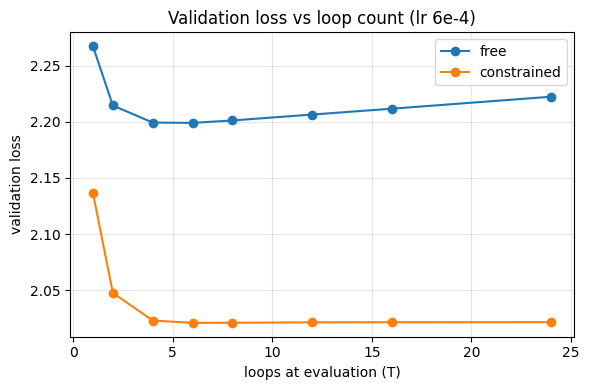

In [33]:
import matplotlib.pyplot as plt

FIG_DIR = f'{RUN_DIR}/figs'
os.makedirs(FIG_DIR, exist_ok=True)
load = lambda name: json.load(open(f'{RUN_DIR}/{name}.json'))
fig, ax = plt.subplots(figsize=(6, 4))
for label, name in [('free', 's1_free_seed0'), ('constrained', 's1_constrained_seed0')]:
    r = load(name)
    Ts = sorted(int(t) for t in r['final'])
    ax.plot(Ts, [r['final'][str(t)]['val_loss'] for t in Ts], marker='o', label=label)
ax.set_xlabel('loops at evaluation (T)')
ax.set_ylabel('validation loss')
ax.set_title('Validation loss vs loop count (lr 6e-4)')
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(f'{FIG_DIR}/fig1_loss_vs_loops.png', dpi=200)
plt.show()

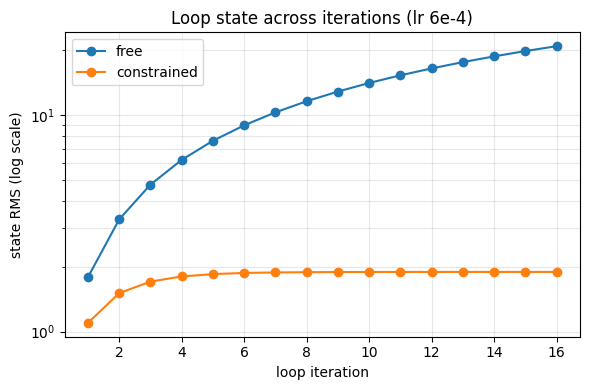

In [34]:
fig, ax = plt.subplots(figsize=(6, 4))
for label, name in [('free', 's1_free_seed0'), ('constrained', 's1_constrained_seed0')]:
    n = load(name)['final_state_norms']
    ax.plot(range(1, len(n) + 1), n, marker='o', label=label)
ax.set_yscale('log')
ax.set_xlabel('loop iteration')
ax.set_ylabel('state RMS (log scale)')
ax.set_title('Loop state across iterations (lr 6e-4)')
ax.legend(); ax.grid(alpha=0.3, which='both')
fig.tight_layout()
fig.savefig(f'{FIG_DIR}/fig2_state_norms.png', dpi=200)
plt.show()

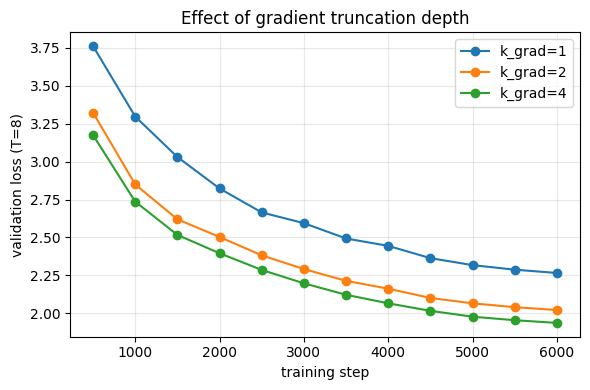

In [35]:
fig, ax = plt.subplots(figsize=(6, 4))
for label, name in [('k_grad=1', 's3_k1'), ('k_grad=2', 's1_constrained_seed0'), ('k_grad=4', 's3_k4')]:
    ev = load(name)['evals']
    ax.plot([e['step'] for e in ev], [e['evals']['8']['val_loss'] for e in ev], marker='o', label=label)
ax.set_xlabel('training step')
ax.set_ylabel('validation loss (T=8)')
ax.set_title('Effect of gradient truncation depth')
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(f'{FIG_DIR}/fig3_kgrad.png', dpi=200)
plt.show()

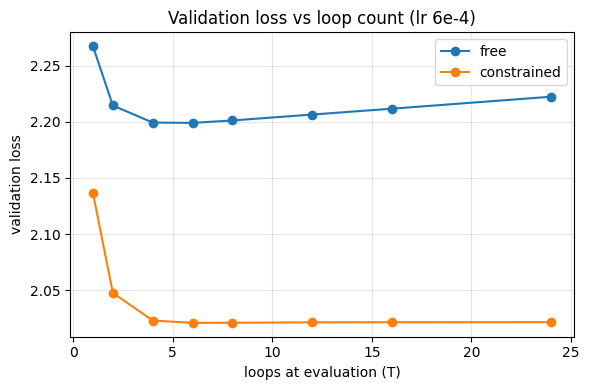

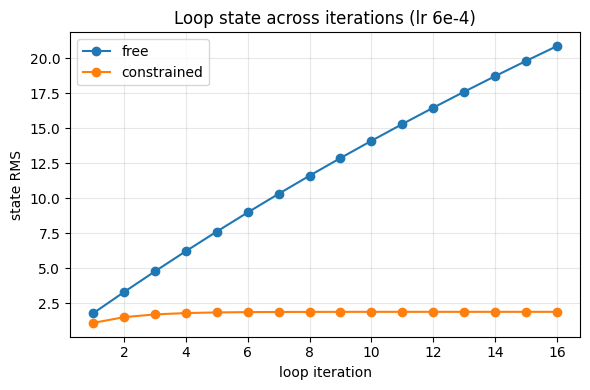

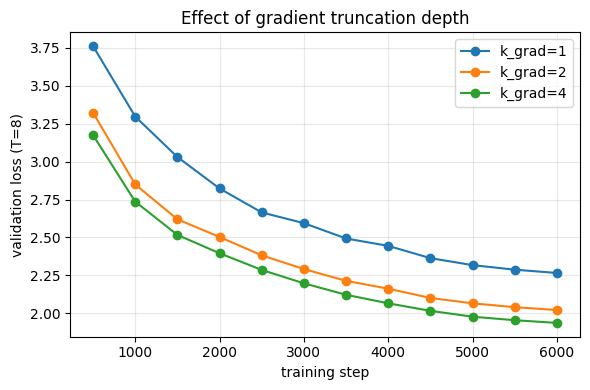

['fig2a_state_free.png', 'fig2b_state_constrained.png', 'fig1_loss_vs_loops.png', 'fig3_kgrad.png', 'fig2_state_norms.png']


In [36]:
FIG_DIR = f'{RUN_DIR}/figs'
os.makedirs(FIG_DIR, exist_ok=True)
load = lambda name: json.load(open(f'{RUN_DIR}/{name}.json'))

# Figure 1: validation loss vs loops at evaluation (Stage 1 and Stage 2 test-time sweep)
fig, ax = plt.subplots(figsize=(6, 4))
for label, name in [('free', 's1_free_seed0'), ('constrained', 's1_constrained_seed0')]:
    r = load(name)
    Ts = sorted(int(t) for t in r['final'])
    ax.plot(Ts, [r['final'][str(t)]['val_loss'] for t in Ts], marker='o', label=label)
ax.set_xlabel('loops at evaluation (T)'); ax.set_ylabel('validation loss')
ax.set_title('Validation loss vs loop count (lr 6e-4)'); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f'{FIG_DIR}/fig1_loss_vs_loops.png', dpi=200); plt.show()

# Figure 2: loop-state RMS across iterations
fig, ax = plt.subplots(figsize=(6, 4))
for label, name in [('free', 's1_free_seed0'), ('constrained', 's1_constrained_seed0')]:
    n = load(name)['final_state_norms']
    ax.plot(range(1, len(n) + 1), n, marker='o', label=label)
ax.set_xlabel('loop iteration'); ax.set_ylabel('state RMS')
ax.set_title('Loop state across iterations (lr 6e-4)'); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f'{FIG_DIR}/fig2_state_norms.png', dpi=200); plt.show()

# Figure 3: validation loss during training for each k_grad
fig, ax = plt.subplots(figsize=(6, 4))
for label, name in [('k_grad=1', 's3_k1'), ('k_grad=2', 's1_constrained_seed0'), ('k_grad=4', 's3_k4')]:
    ev = load(name)['evals']
    ax.plot([e['step'] for e in ev], [e['evals']['8']['val_loss'] for e in ev], marker='o', label=label)
ax.set_xlabel('training step'); ax.set_ylabel('validation loss (T=8)')
ax.set_title('Effect of gradient truncation depth'); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f'{FIG_DIR}/fig3_kgrad.png', dpi=200); plt.show()

print(os.listdir(FIG_DIR))

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, json
RUN_DIR = '/content/drive/MyDrive/looped/runs'
print(sorted(f for f in os.listdir(RUN_DIR) if f.endswith('.json')))

In [37]:
need = ['Config', 'LoopedLM', 'sample_loops', 'evaluate', 'state_norms',
        'make_optimizer', 'lr_at', 'run', 'VAL', 'train', 'RUN_DIR']
print({n: (n in globals()) for n in need})

{'Config': True, 'LoopedLM': True, 'sample_loops': True, 'evaluate': True, 'state_norms': True, 'make_optimizer': True, 'lr_at': True, 'run': True, 'VAL': True, 'train': True, 'RUN_DIR': True}


In [ ]:
STEPS = 6000
r_con1 = run("s1_constrained_seed1", inject="constrained", k_grad=2, steps=STEPS, seed=1)

In [ ]:
r_free1 = run("s1_free_seed1", inject="free", k_grad=2, steps=STEPS, seed=1)

In [38]:
summarize('s1_free_seed1')
summarize('s1_constrained_seed1')

== s1_free_seed1
  grad norm max/mean: 2.47 / 0.67 | clipped frac: 0.017
  max_A first/last/peak: 1.0 1.023 1.046
  state norms: [1.88, 3.44, 4.95, 6.42, 7.84, 9.22, 10.55, 11.85, 13.12, 14.35, 15.54, 16.71, 17.84, 18.94, 20.01, 21.06]
  spikes/nonfinite: 0 0 | peak mem GB: 6.6
== s1_constrained_seed1
  grad norm max/mean: 2.74 / 0.82 | clipped frac: 0.023
  max_A first/last/peak: 0.5 0.567 0.57
  state norms: [1.06, 1.48, 1.66, 1.76, 1.8, 1.82, 1.83, 1.84, 1.84, 1.84, 1.84, 1.84, 1.84, 1.84, 1.84, 1.84]
  spikes/nonfinite: 0 0 | peak mem GB: 6.6
